In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import joblib

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [2]:
X, y = make_moons(
    n_samples=2000,
    noise=0.25,
    random_state=SEED
)

df = pd.DataFrame(X, columns=["Feature_1", "Feature_2"])
df["Target"] = y

print(df.head())
print(df["Target"].value_counts())
print("Dataset Shape:", X.shape)

   Feature_1  Feature_2  Target
0   1.582305   0.366876       1
1   0.327654   0.982366       0
2   0.488270  -0.246765       1
3  -0.937421  -0.029429       0
4   0.634397  -0.412224       1
Target
1    1000
0    1000
Name: count, dtype: int64
Dataset Shape: (2000, 2)


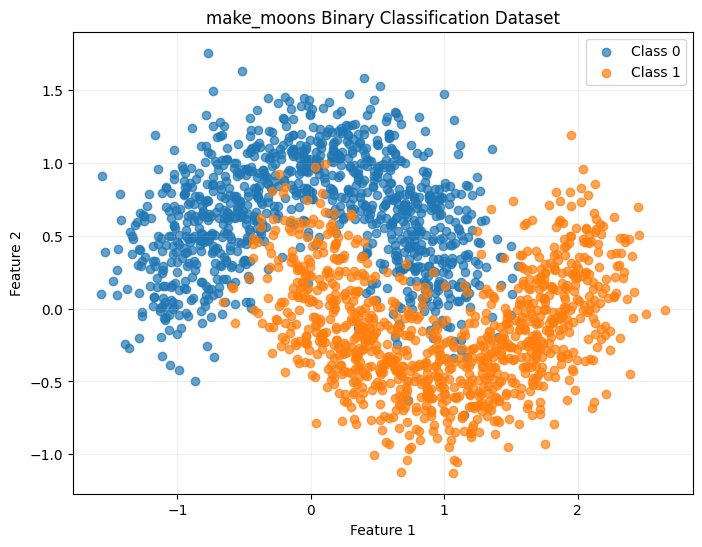

In [3]:
plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], label="Class 0", alpha=0.7)
plt.scatter(X[y == 1, 0], X[y == 1, 1], label="Class 1", alpha=0.7)
plt.title("make_moons Binary Classification Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 1600
Testing Samples: 400


In [5]:
model = Sequential([
    Input(shape=(2,)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 193 (772.00 B)

 Trainable params: 193 (772.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.7086 - loss: 0.6383 - val_accuracy: 0.7188 - val_loss: 0.6066
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7992 - loss: 0.5466 - val_accuracy: 0.7781 - val_loss: 0.5254
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8453 - loss: 0.4552 - val_accuracy: 0.8125 - val_loss: 0.4524
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8641 - loss: 0.3820 - val_accuracy: 0.8281 - val_loss: 0.4041
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8711 - loss: 0.3394 - val_accuracy: 0.8250 - val_loss: 0.3799
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8680 - loss: 0.3182 - val_accuracy: 0.8344 - val_loss: 0.3691
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8711 - loss: 0.3072 - val_accuracy: 0.8344 - val_loss: 0.3632
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8750 - loss: 0.3000 - val_accuracy: 0.8344 - 

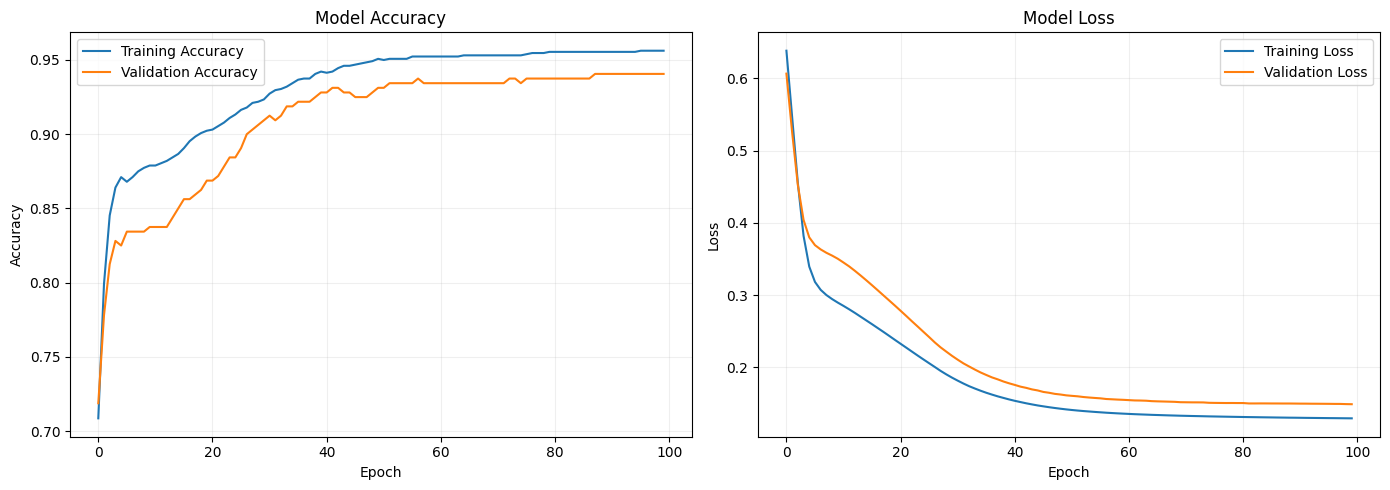

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["accuracy"], label="Training Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(history.history["loss"], label="Training Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [8]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

y_prob = model.predict(X_test_scaled, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

results = pd.DataFrame({
    "Metric": ["Test Loss", "Test Accuracy", "Precision", "Recall", "F1-Score"],
    "Value": [test_loss, accuracy, precision, recall, f1]
})

display(results.round(4))
print(classification_report(y_test, y_pred, zero_division=0))

,Metric,Value
0,Test Loss,0.1637
1,Test Accuracy,0.9250
2,Precision,0.9167
3,Recall,0.9350
4,F1-Score,0.9257


              precision    recall  f1-score   support

           0       0.93      0.92      0.92       200
           1       0.92      0.94      0.93       200

    accuracy                           0.93       400
   macro avg       0.93      0.93      0.92       400
weighted avg       0.93      0.93      0.92       400



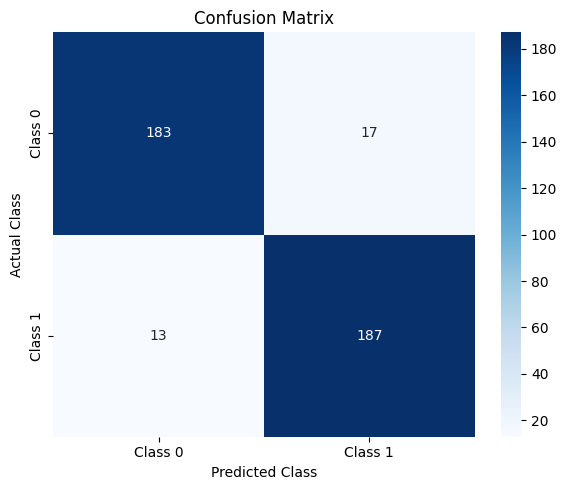

In [9]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

In [ ]:
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
grid_scaled = scaler.transform(grid)
probabilities = model.predict(grid_scaled, verbose=0)
Z = (probabilities >= 0.5).astype(int).reshape(xx.shape)

plt.figure(figsize=(9, 7))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
plt.scatter(X[y == 0, 0], X[y == 0, 1], label="Class 0", edgecolors="black", s=25)
plt.scatter(X[y == 1, 0], X[y == 1, 1], label="Class 1", edgecolors="black", s=25)
plt.title("ANN Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
new_sample = np.array([[0.5, 0.2]])
new_sample_scaled = scaler.transform(new_sample)

probability = model.predict(new_sample_scaled, verbose=0)[0][0]
predicted_class = int(probability >= 0.5)

print("Input Sample:", new_sample[0])
print("Class 0 Probability:", round(1 - probability, 4))
print("Class 1 Probability:", round(probability, 4))
print("Predicted Class:", predicted_class)

Input Sample: [0.5 0.2]
Class 0 Probability: 0.3155
Class 1 Probability: 0.6845
Predicted Class: 1


In [11]:
os.makedirs("ann_project", exist_ok=True)

model.save("ann_project/ann_make_moons.keras")
joblib.dump(scaler, "ann_project/scaler.joblib")
results.to_csv("ann_project/evaluation_results.csv", index=False)

print("Model and evaluation results saved successfully.")

Model and evaluation results saved successfully.


In [12]:
loaded_model = load_model("ann_project/ann_make_moons.keras")
loaded_scaler = joblib.load("ann_project/scaler.joblib")

sample = np.array([[0.5, 0.2]])
sample_scaled = loaded_scaler.transform(sample)

probability = loaded_model.predict(sample_scaled, verbose=0)[0][0]

print("Predicted Class:", int(probability >= 0.5))
print("Class 1 Probability:", round(probability, 4))

Predicted Class: 1
Class 1 Probability: 0.6845


In [13]:
import joblib
import numpy as np
from tensorflow.keras.models import load_model

loaded_model = load_model("ann_project/ann_make_moons.keras")
loaded_scaler = joblib.load("ann_project/scaler.joblib")

sample = np.array([[0.5, 0.2]])
sample_scaled = loaded_scaler.transform(sample)

probability = float(loaded_model.predict(sample_scaled, verbose=0)[0][0])
predicted_class = int(probability >= 0.5)

print("Model loaded successfully")
print("Scaler loaded successfully")
print("Predicted Class:", predicted_class)
print("Class 1 Probability:", round(probability, 4))

Model loaded successfully
Scaler loaded successfully
Predicted Class: 1
Class 1 Probability: 0.6845
